# FraudShield — Analyse Exploratoire (EDA)

**Dataset** : IEEE-CIS Fraud Detection (Kaggle)
- 590 340 transactions bancaires
- 394 + 41 features
- Taux de fraude : ~3.5%

**Objectif** : comprendre la distribution des fraudes avant de construire le modèle

---

In [3]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import TRAIN_TRANSACTION, TRAIN_IDENTITY

plt.style.use('seaborn-v0_8-whitegrid')
NAVY, GOLD = '#1B2A4A', '#C9A84C'
print('✓ Setup OK')

2026-10-12 17:07:17.009 | INFO     | src.config:<module>:64 - Config FraudShield chargée — DB : fraudshield@localhost


✓ Setup OK


In [13]:
%matplotlib inline

In [5]:
# Charger un sous-ensemble pour l'EDA (50K lignes)
df = pd.read_csv(TRAIN_TRANSACTION, nrows=50000, low_memory=False)
print(f"Shape : {df.shape}")
print(f"Taux de fraude : {df['isFraud'].mean()*100:.2f}%")
df.head(3)

Shape : (50000, 394)
Taux de fraude : 2.71%


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Déséquilibre des classes

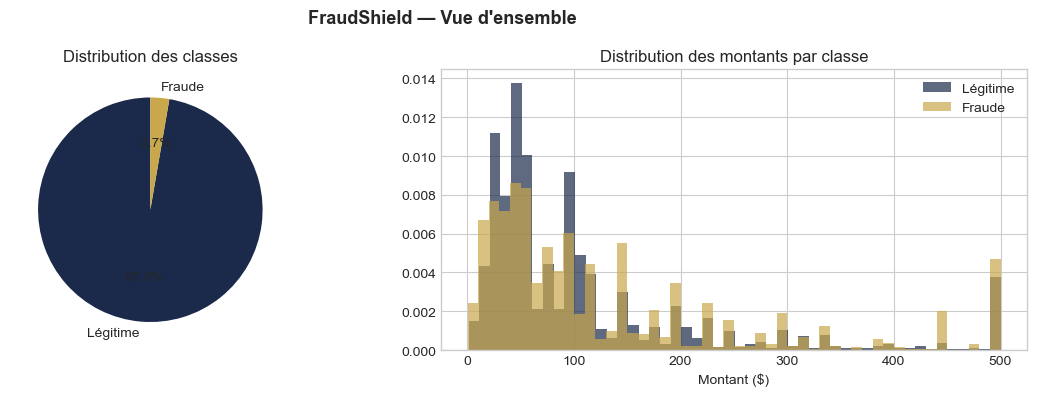

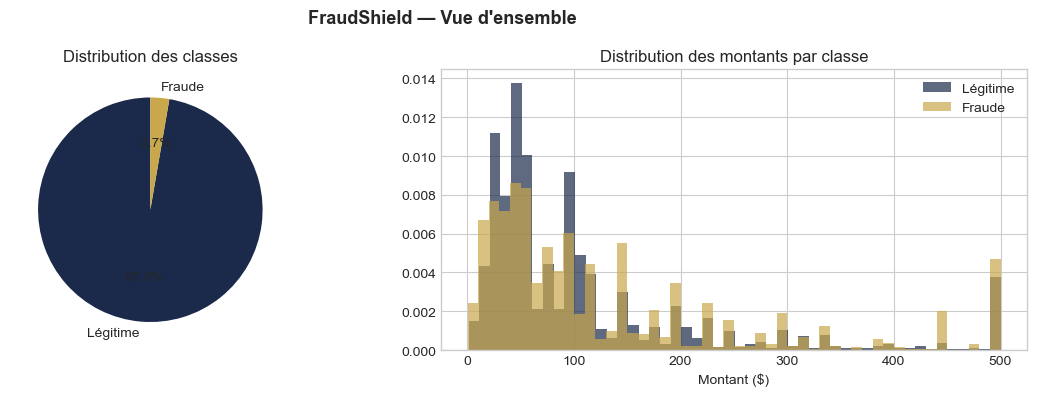

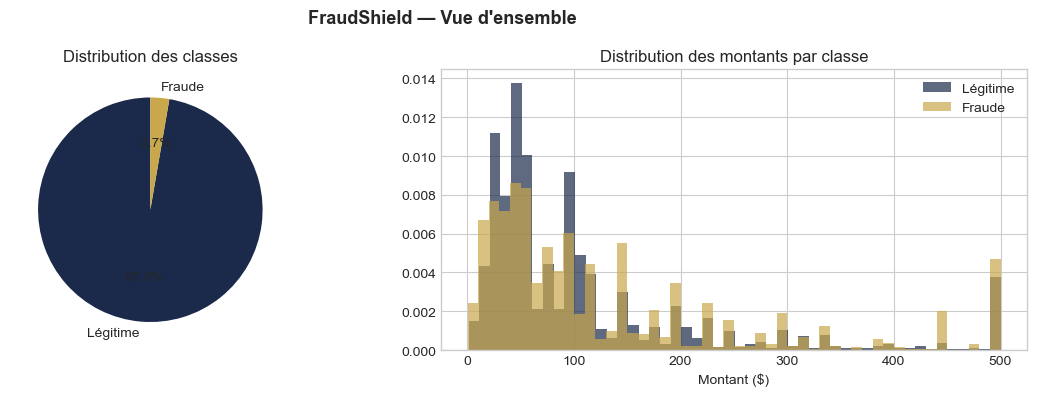

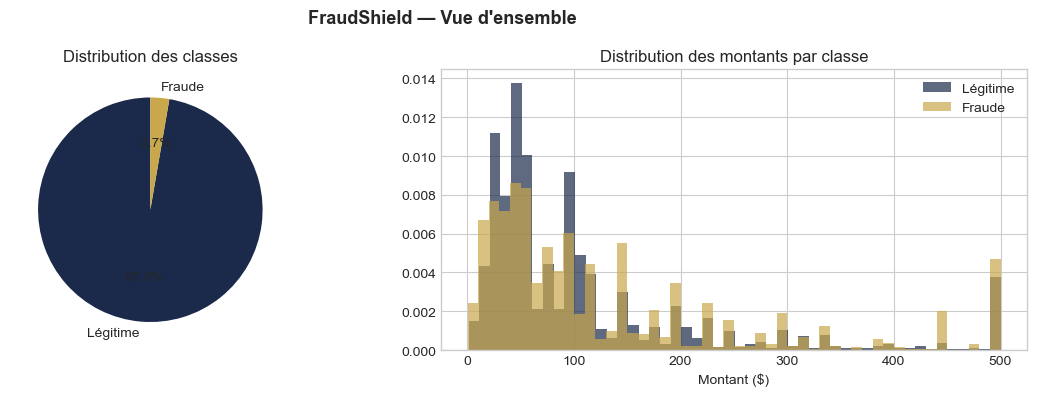

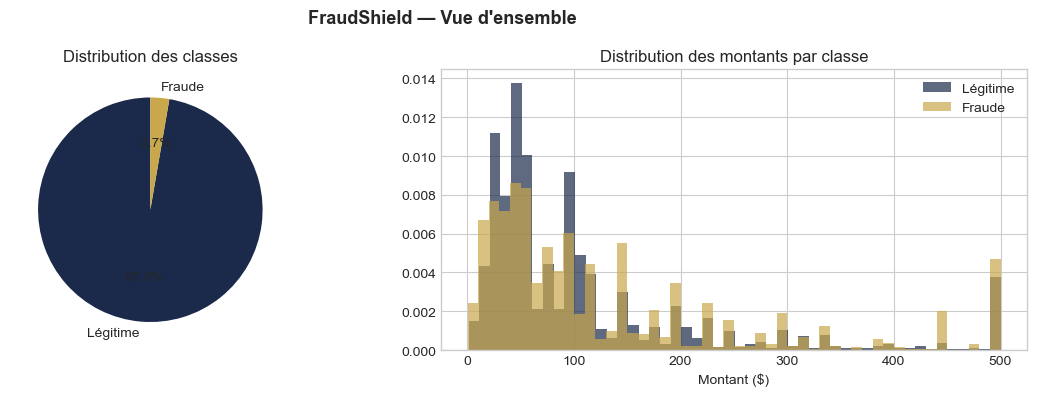

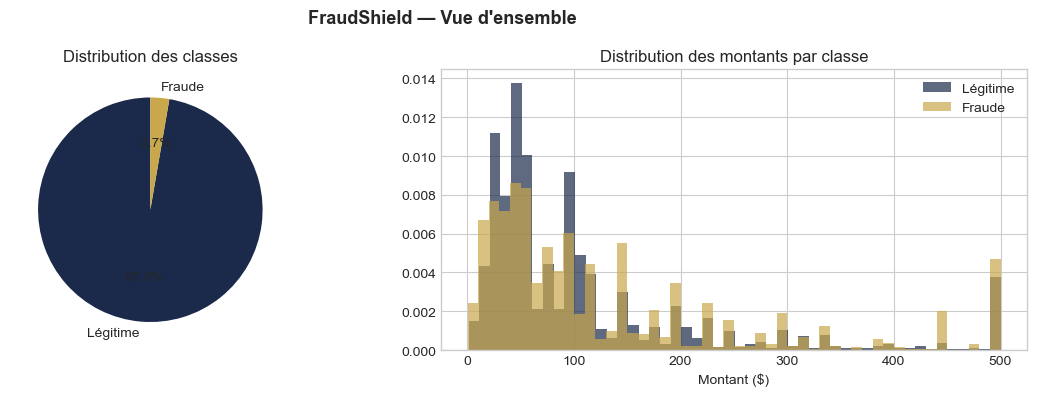

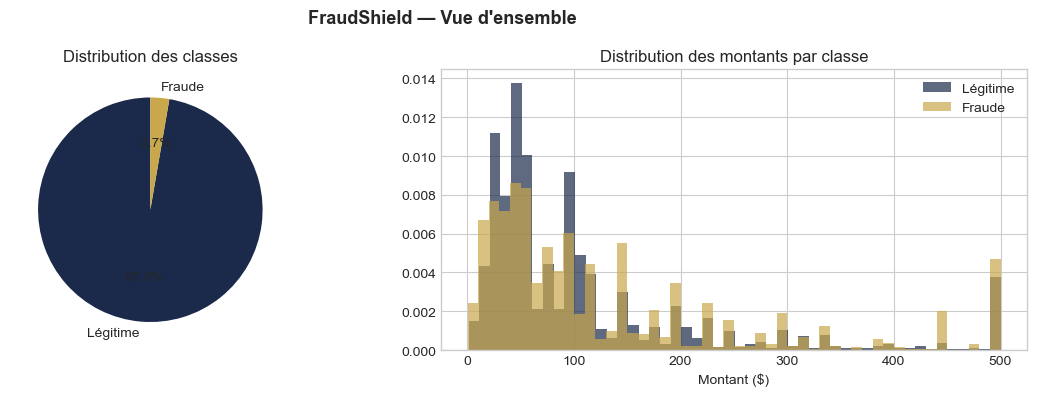

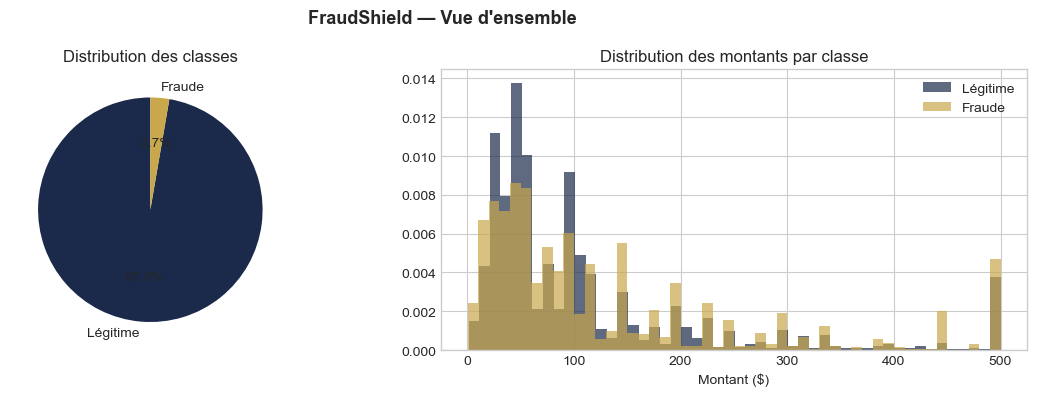

<Figure size 640x480 with 0 Axes>

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
fraud_counts = df['isFraud'].value_counts()
axes[0].pie(fraud_counts, labels=['Légitime', 'Fraude'],
            colors=[NAVY, GOLD], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Distribution des classes')

# Montant par classe
df.groupby('isFraud')['TransactionAmt'].apply(list)
axes[1].hist(df[df.isFraud==0]['TransactionAmt'].clip(0,500),
             bins=50, alpha=0.7, color=NAVY, label='Légitime', density=True)
axes[1].hist(df[df.isFraud==1]['TransactionAmt'].clip(0,500),
             bins=50, alpha=0.7, color=GOLD, label='Fraude', density=True)
axes[1].set_xlabel('Montant ($)')
axes[1].set_title('Distribution des montants par classe')
axes[1].legend()

plt.suptitle('FraudShield — Vue d\'ensemble', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
plt.savefig('C:/Users/asus/Desktop/FraudShield/reports/eda_overview.png', dpi=150, bbox_inches='tight')

## 2. Taux de fraude par ProductCD et Type de carte

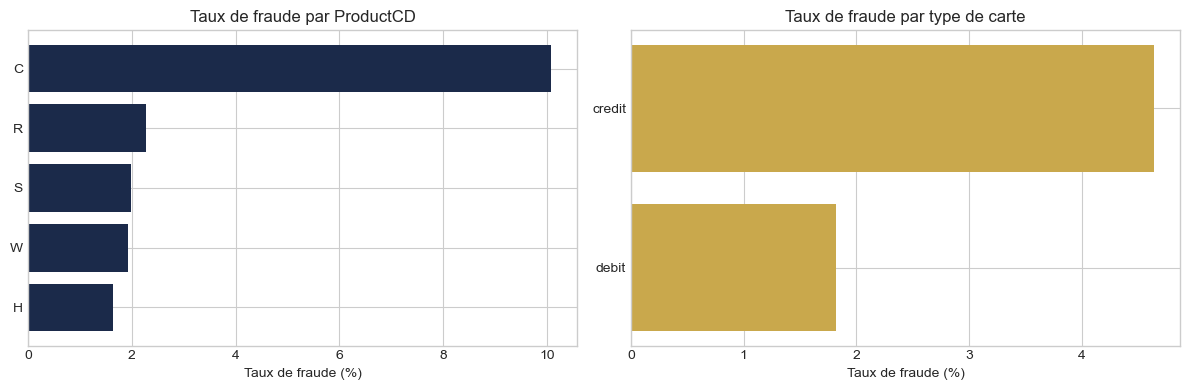

<Figure size 640x480 with 0 Axes>

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ProductCD
prod_stats = df.groupby('ProductCD')['isFraud'].agg(['mean','count']).reset_index()
prod_stats = prod_stats[prod_stats['count'] > 100]
prod_stats = prod_stats.sort_values('mean', ascending=True)
axes[0].barh(prod_stats['ProductCD'], prod_stats['mean']*100, color=NAVY)
axes[0].set_xlabel('Taux de fraude (%)')
axes[0].set_title('Taux de fraude par ProductCD')

# Type de carte
card_stats = df.groupby('card6')['isFraud'].agg(['mean','count']).reset_index()
card_stats = card_stats[card_stats['count'] > 100].sort_values('mean', ascending=True)
axes[1].barh(card_stats['card6'], card_stats['mean']*100, color=GOLD)
axes[1].set_xlabel('Taux de fraude (%)')
axes[1].set_title('Taux de fraude par type de carte')

plt.tight_layout()
plt.show()
plt.savefig('../reports/eda_fraud_by_type.png', dpi=150, bbox_inches='tight')


## 3. Profil temporel de la fraude

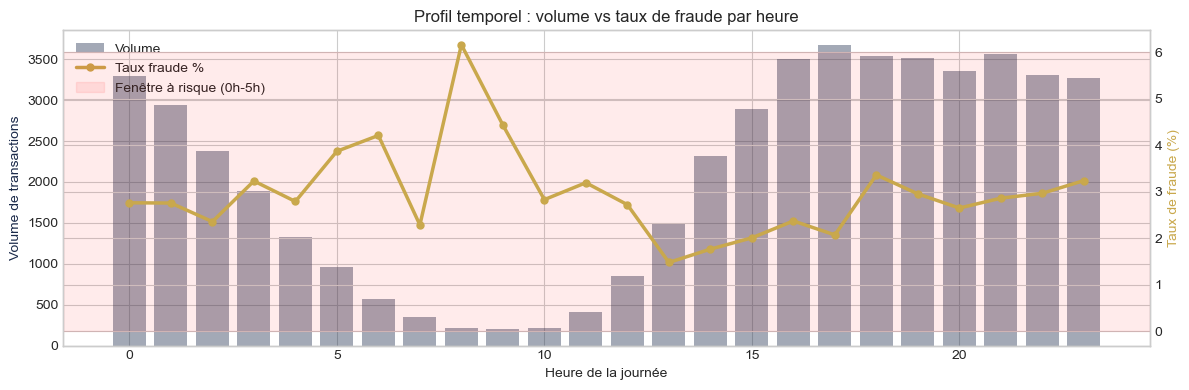

In [16]:
df['hour'] = (df['TransactionDT'] % 86400) // 3600
hour_stats = df.groupby('hour')['isFraud'].agg(['mean','count']).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()

ax1.bar(hour_stats['hour'], hour_stats['count'], color=NAVY, alpha=0.4, label='Volume')
ax2.plot(hour_stats['hour'], hour_stats['mean']*100, color=GOLD,
         linewidth=2.5, marker='o', markersize=5, label='Taux fraude %')
ax2.axhspan(0, 6, alpha=0.08, color='red', label='Fenêtre à risque (0h-5h)')

ax1.set_xlabel('Heure de la journée')
ax1.set_ylabel('Volume de transactions', color=NAVY)
ax2.set_ylabel('Taux de fraude (%)', color=GOLD)
ax1.set_title('Profil temporel : volume vs taux de fraude par heure')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig('../reports/eda_temporal.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Analyse des NaN (taux de valeurs manquantes)

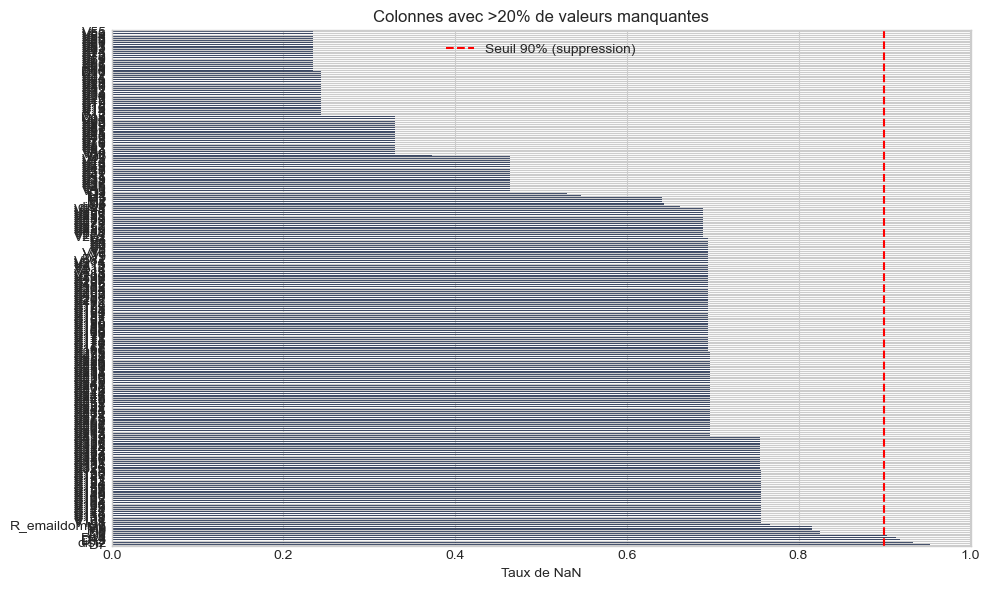


Colonnes >90% NaN (à supprimer) : 6
Colonnes >50% NaN              : 192


In [17]:
nan_rate = df.isnull().mean().sort_values(ascending=False)
nan_rate_high = nan_rate[nan_rate > 0.2]

plt.figure(figsize=(10, 6))
nan_rate_high.plot.barh(color=NAVY, alpha=0.8)
plt.axvline(0.9, color='red', linestyle='--', linewidth=1.5, label='Seuil 90% (suppression)')
plt.xlabel('Taux de NaN')
plt.title('Colonnes avec >20% de valeurs manquantes')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/eda_nan_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nColonnes >90% NaN (à supprimer) : {(nan_rate > 0.9).sum()}")
print(f"Colonnes >50% NaN              : {(nan_rate > 0.5).sum()}")